# Task 3: Customer Cohort & Churn Analytics

Datheon Internship • IBM Telco Customer Churn dataset

Objective: quantify churn, compare retention across tenure bands and contract types, identify risk segments, and recommend retention actions.

**Method limitation:** The source has tenure but no signup date or observation date. The tenure-band matrix is a cross-sectional retention segmentation, not a true acquisition-vintage cohort curve.

In [1]:
import base64, gzip, io, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style='whitegrid')
DATA_B64 = '''...'''
raw = pd.read_csv(io.BytesIO(gzip.decompress(base64.b64decode(DATA_B64))))
print('Raw shape:', raw.shape)
display(raw.head())

Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data cleaning and quality checks

In [2]:
df=raw.copy()
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')
df['tenure']=pd.to_numeric(df['tenure'],errors='coerce')
df['MonthlyCharges']=pd.to_numeric(df['MonthlyCharges'],errors='coerce')
df=df.drop_duplicates(subset=['customerID']).copy()
df['Churn Flag']=df['Churn'].str.strip().str.lower().eq('yes').astype(int)
df['Retained Flag']=1-df['Churn Flag']
df['Tenure Band']=pd.cut(df['tenure'],[-1,12,24,48,72],labels=['0–12 months','13–24 months','25–48 months','49–72 months'])
print('Clean shape:',df.shape,'| duplicate IDs:',df.customerID.duplicated().sum())
display(df.isna().sum().to_frame('Missing values'))

Clean shape: (7043, 24) | duplicate IDs: 0


,Missing values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## 2. Baseline churn and retention KPIs

In [3]:
n=len(df); churned=int(df['Churn Flag'].sum()); churn_rate=churned/n*100; retention_rate=100-churn_rate
kpis=pd.DataFrame({'Metric':['Total customers','Churned customers','Churn rate (%)','Retention rate (%)'],'Value':[n,churned,churn_rate,retention_rate]})
display(kpis)

,Metric,Value
0,Total customers,7043.000000
1,Churned customers,1869.000000
2,Churn rate (%),26.536987
3,Retention rate (%),73.463013


## 3. Tenure-band retention matrix by contract

Contract,Month-to-month,One year,Two year
Tenure Band,,,
0–12 months,48.6,89.5,100.0
13–24 months,62.3,91.9,100.0
25–48 months,67.1,89.4,97.8
49–72 months,74.0,87.1,96.7


Contract,Month-to-month,One year,Two year
Tenure Band,,,
0–12 months,1994,124,68
13–24 months,737,197,90
25–48 months,802,518,274
49–72 months,342,634,1263


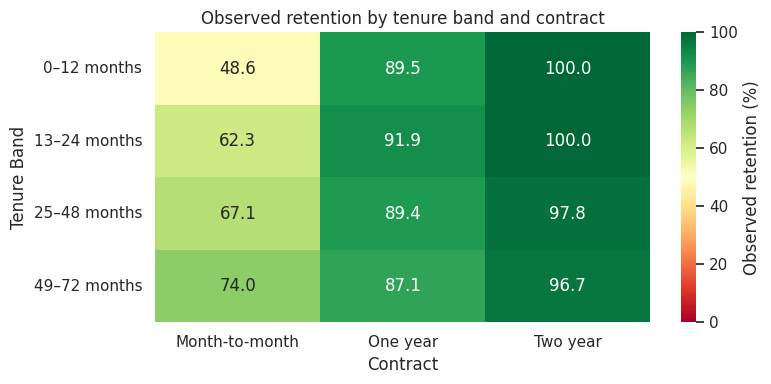

In [4]:
retention_matrix=df.pivot_table(index='Tenure Band',columns='Contract',values='Retained Flag',aggfunc='mean',observed=False)*100
counts=df.pivot_table(index='Tenure Band',columns='Contract',values='customerID',aggfunc='count',observed=False)
display(retention_matrix.round(1)); display(counts)
plt.figure(figsize=(8,4)); sns.heatmap(retention_matrix,annot=True,fmt='.1f',cmap='RdYlGn',vmin=0,vmax=100,cbar_kws={'label':'Observed retention (%)'})
plt.title('Observed retention by tenure band and contract'); plt.tight_layout(); plt.show()

## 4. Churn by contract, payment method, internet service and support

In [5]:
def churn_summary(col):
    x=df.groupby(col,dropna=False)['Churn Flag'].agg(Customers='count',Churned='sum',Churn_Rate='mean')
    x['Churn_Rate']*=100
    return x.sort_values('Churn_Rate',ascending=False)
for col in ['Contract','PaymentMethod','InternetService','TechSupport','OnlineSecurity','Tenure Band']:
    print('\n'+col); display(churn_summary(col).style.format({'Churn_Rate':'{:.2f}%'}))


Contract


,Customers,Churned,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.71%
One year,1473,166,11.27%
Two year,1695,48,2.83%



PaymentMethod


,Customers,Churned,Churn_Rate
PaymentMethod,,,
Electronic check,2365,1071,45.29%
Mailed check,1612,308,19.11%
Bank transfer (automatic),1544,258,16.71%
Credit card (automatic),1522,232,15.24%



InternetService


,Customers,Churned,Churn_Rate
InternetService,,,
Fiber optic,3096,1297,41.89%
DSL,2421,459,18.96%
No,1526,113,7.40%


... (2 outputs left out)


OnlineSecurity


,Customers,Churned,Churn_Rate
OnlineSecurity,,,
No,3498,1461,41.77%
Yes,2019,295,14.61%
No internet service,1526,113,7.40%



Tenure Band


,Customers,Churned,Churn_Rate
Tenure Band,,,
0–12 months,2186,1037,47.44%
13–24 months,1024,294,28.71%
25–48 months,1594,325,20.39%
49–72 months,2239,213,9.51%


## 5. Visual analysis

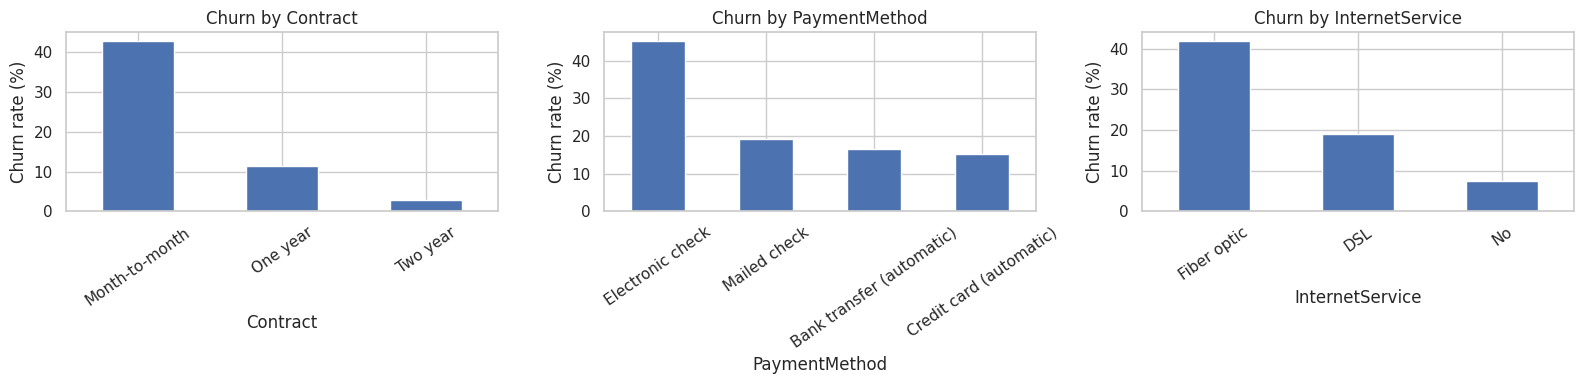

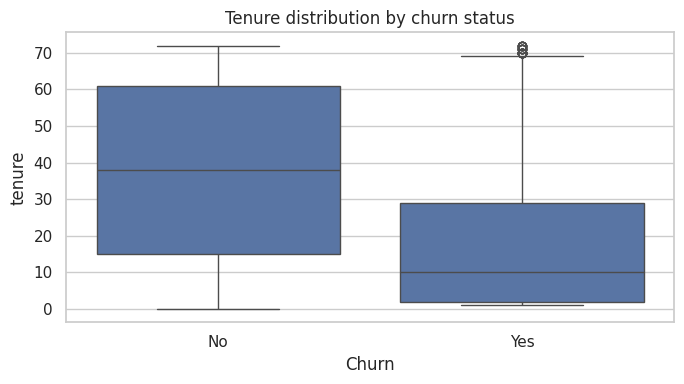

In [6]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,col in zip(axes,['Contract','PaymentMethod','InternetService']):
    churn_summary(col)['Churn_Rate'].plot(kind='bar',ax=ax,title='Churn by '+col); ax.set_ylabel('Churn rate (%)'); ax.tick_params(axis='x',rotation=35)
plt.tight_layout(); plt.show()
plt.figure(figsize=(7,4)); sns.boxplot(data=df,x='Churn',y='tenure'); plt.title('Tenure distribution by churn status'); plt.tight_layout(); plt.show()

## 6. Findings and retention recommendations

In [7]:
cs=churn_summary('Contract'); ps=churn_summary('PaymentMethod'); ins=churn_summary('InternetService'); ts=churn_summary('TechSupport')
findings=[f'Overall churn is {churn_rate:.2f}% ({churned:,} of {n:,} customers).',f'Month-to-month churn is {cs.loc["Month-to-month","Churn_Rate"]:.2f}% versus {cs.loc["Two year","Churn_Rate"]:.2f}% for two-year contracts.',f'Electronic-check customers have {ps.loc["Electronic check","Churn_Rate"]:.2f}% churn, the highest payment-method rate.',f'Fiber-optic customers have {ins.loc["Fiber optic","Churn_Rate"]:.2f}% churn.',f'Customers without TechSupport have {ts.loc["No","Churn_Rate"]:.2f}% churn.']
for i,x in enumerate(findings,1): display(Markdown(f'**Finding {i}.** {x}'))
display(Markdown('**Recommendations:** (1) Offer transparent annual-contract incentives. (2) Simplify automatic payment setup and billing education. (3) Audit fiber reliability, installation, price-value and support response. (4) Introduce 30/60/90-day onboarding for newer customers. (5) Test support/security bundles with controlled experiments.'))

**Finding 1.** Overall churn is 26.54% (1,869 of 7,043 customers).

**Finding 2.** Month-to-month churn is 42.71% versus 2.83% for two-year contracts.

**Finding 3.** Electronic-check customers have 45.29% churn, the highest payment-method rate.

**Finding 4.** Fiber-optic customers have 41.89% churn.

**Finding 5.** Customers without TechSupport have 41.64% churn.

**Recommendations:** (1) Offer transparent annual-contract incentives. (2) Simplify automatic payment setup and billing education. (3) Audit fiber reliability, installation, price-value and support response. (4) Introduce 30/60/90-day onboarding for newer customers. (5) Test support/security bundles with controlled experiments.

## 7. Conclusion and limitations

The overall churn rate is approximately 26.5%. Contract, payment method, internet service and tenure are useful descriptive dimensions for identifying customers who may benefit from retention outreach. Validate interventions with controlled tests.

**Limitation:** Without signup and observation dates, this dataset cannot support a true time-based acquisition cohort or survival curve. The tenure-band matrix is a cross-sectional proxy; observed associations do not establish causation.